# **YOLOV8**

In [ ]:
!nvidia-smi

Fri Apr 10 11:05:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   29C    P0             42W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:

!pip install ultralytics==8.2.103 -q

from IPython import display
display.clear_output()

!yolo settings sync=False

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.2.103 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Setup complete ✅ (12 CPUs, 83.5 GB RAM, 43.6/235.7 GB disk)


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

In [ ]:
!mkdir -p {HOME}/datasets
%cd {HOME}/datasets

/content/datasets


In [ ]:
!pip install roboflow

from roboflow import Roboflow
api_key = "YOUR_ROBOFLOW_API_KEY"
workspace_name = "YOUR_ROBOFLOW_WORKSPACE"
project_slug = "YOUR_PROJECT_SLUG"
if api_key == "YOUR_ROBOFLOW_API_KEY" or workspace_name == "YOUR_ROBOFLOW_WORKSPACE" or project_slug == "YOUR_PROJECT_SLUG":
    raise ValueError("Please add your Roboflow API key, workspace, and project slug before running this cell.")
rf = Roboflow(api_key=api_key)
project = rf.workspace(workspace_name).project(project_slug)
version = project.version(1)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...


In [ ]:
import zipfile
import os

zip_path = '/content/datasets/Skin-Cancer-1/roboflow.zip'  # Buraya zip dosyanın tam adını yaz
extract_path = '/content/datasets/Skin-Cancer-1'

if not os.path.exists(extract_path):
    os.makedirs(extract_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Dosyalar başarıyla {extract_path} klasörüne çıkartıldı.")

Dosyalar başarıyla /content/datasets/Skin-Cancer-1 klasörüne çıkartıldı.


In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolov8s.pt data={dataset.location}/data.yaml epochs=25 imgsz=800 batch=8 plots=True

/content
100% 21.5M/21.5M [00:00<00:00, 159MB/s]
New https://pypi.org/project/ultralytics/8.4.36 available 😃 Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.2.103 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/content/datasets/Skin-Cancer-1/data.yaml, epochs=25, time=None, patience=100, batch=8, imgsz=800, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnosti

/content


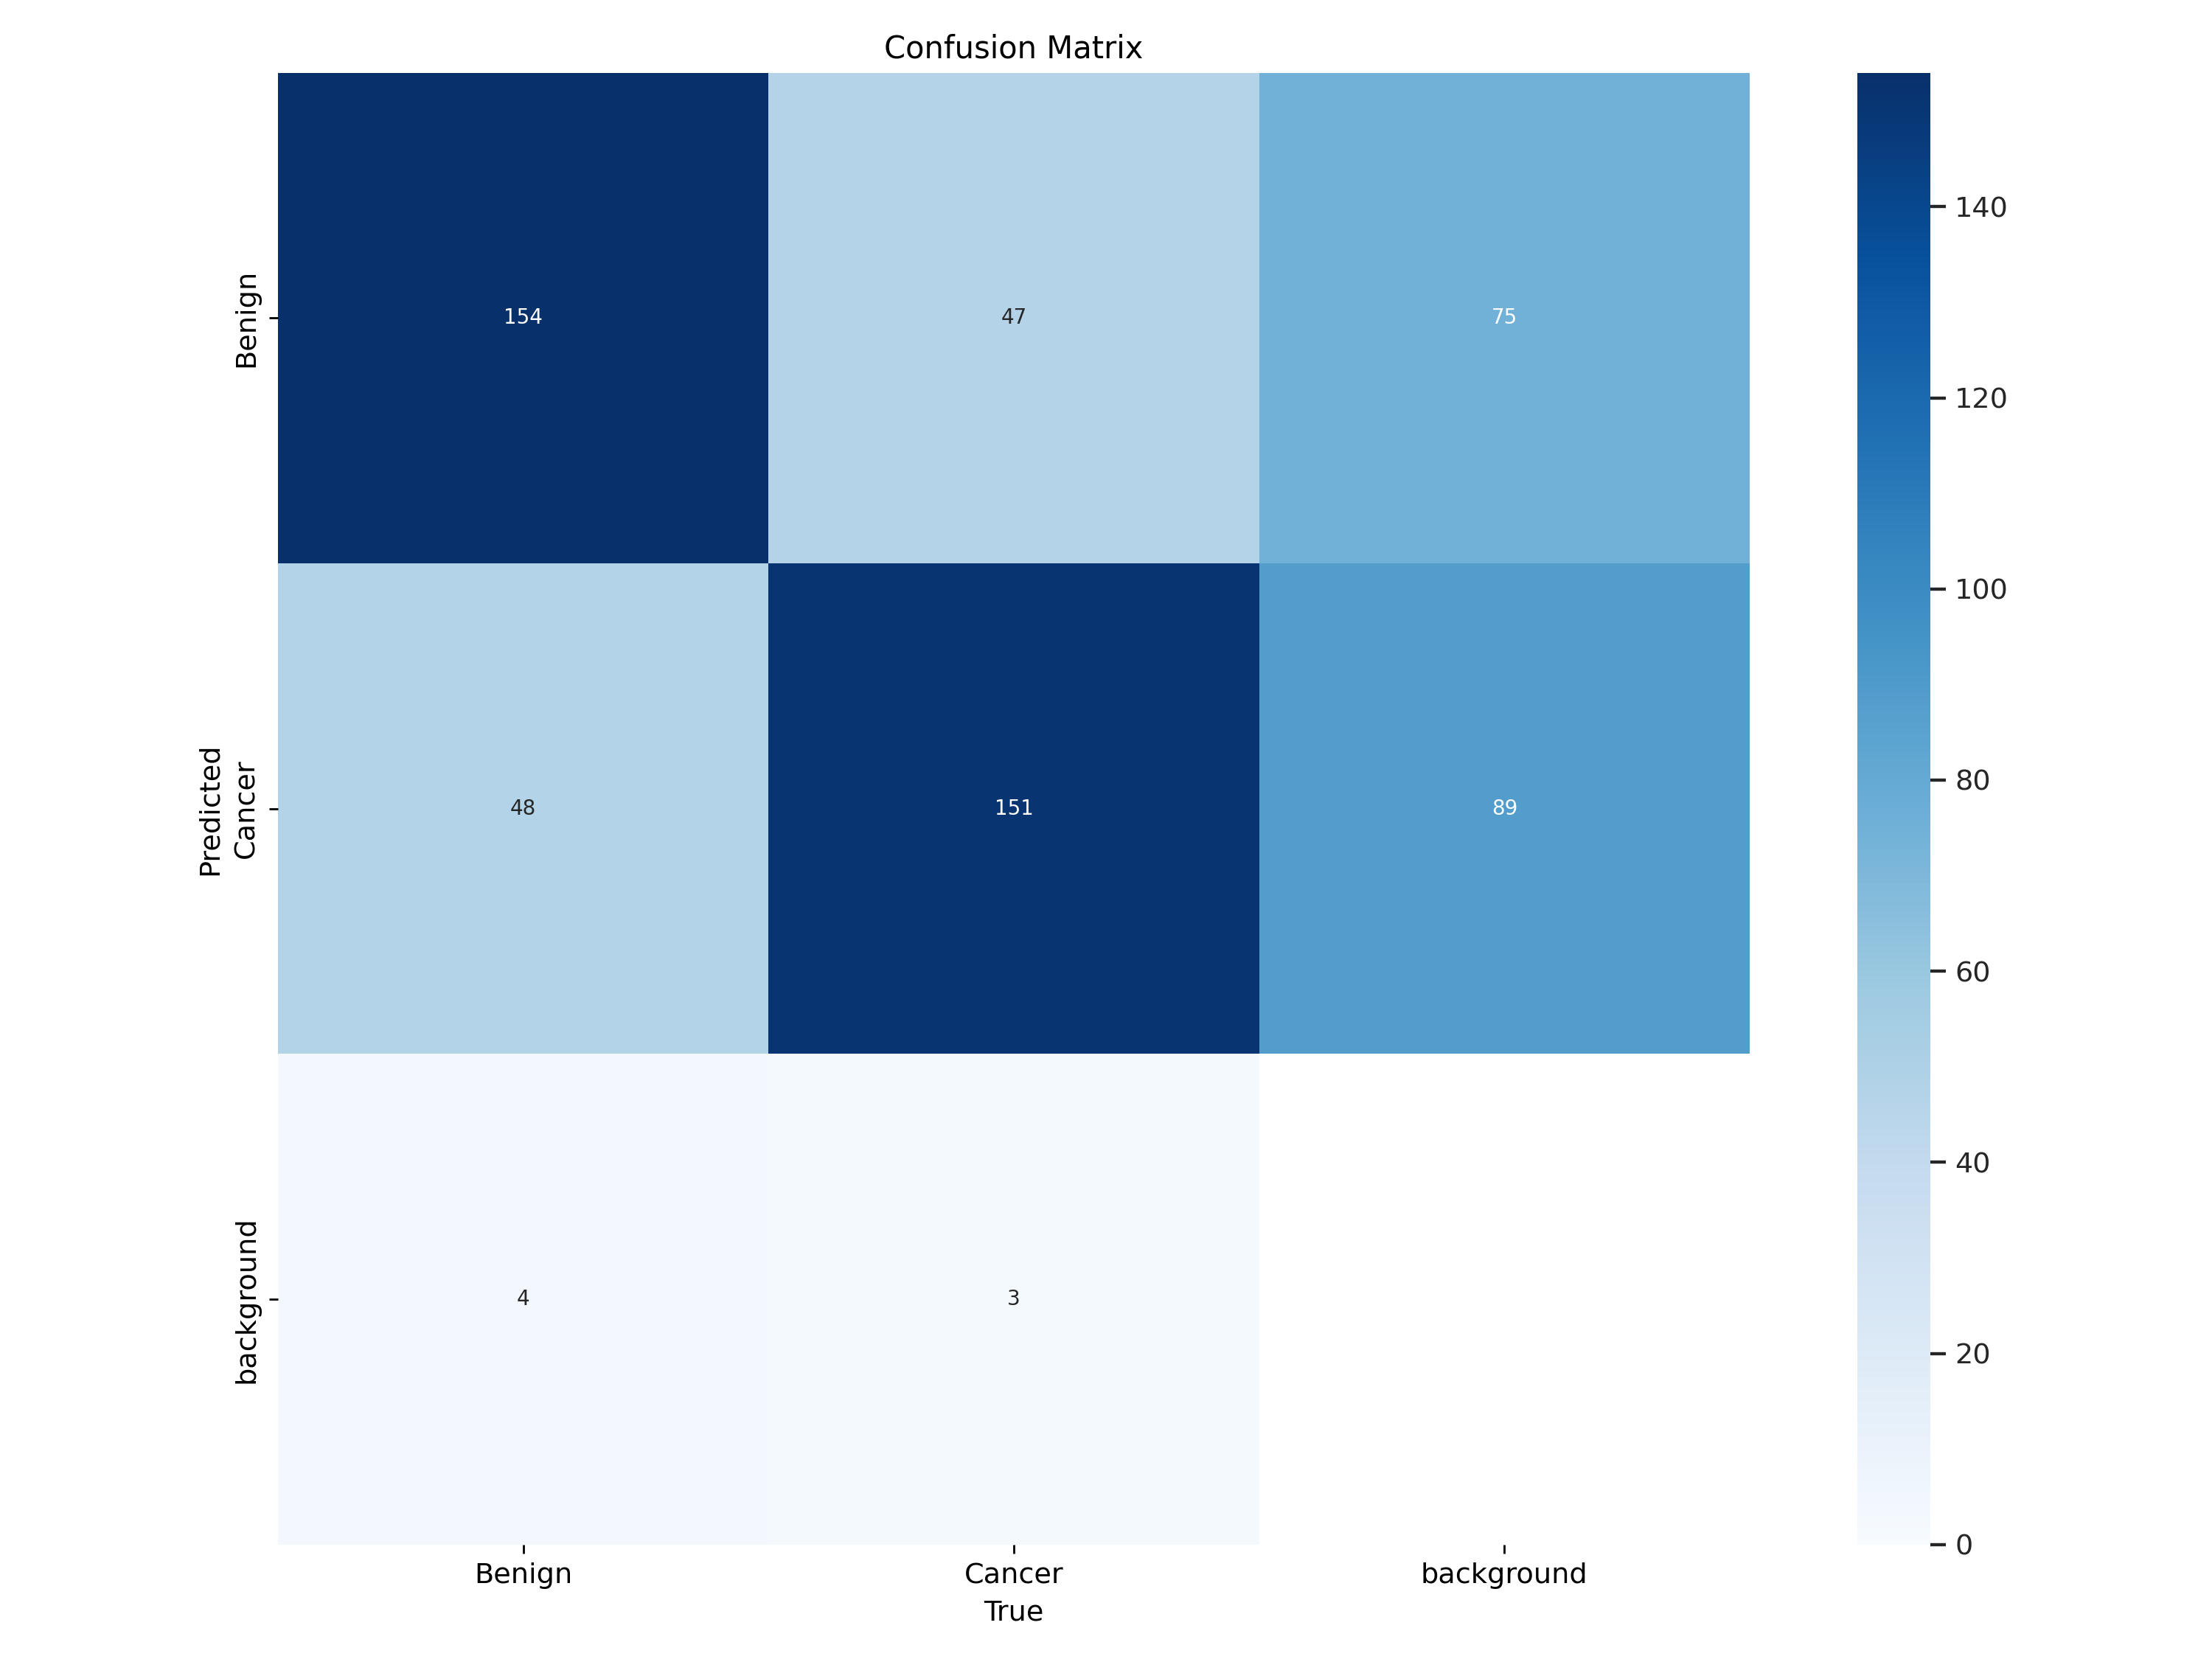

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/confusion_matrix.png', width=600)

/content


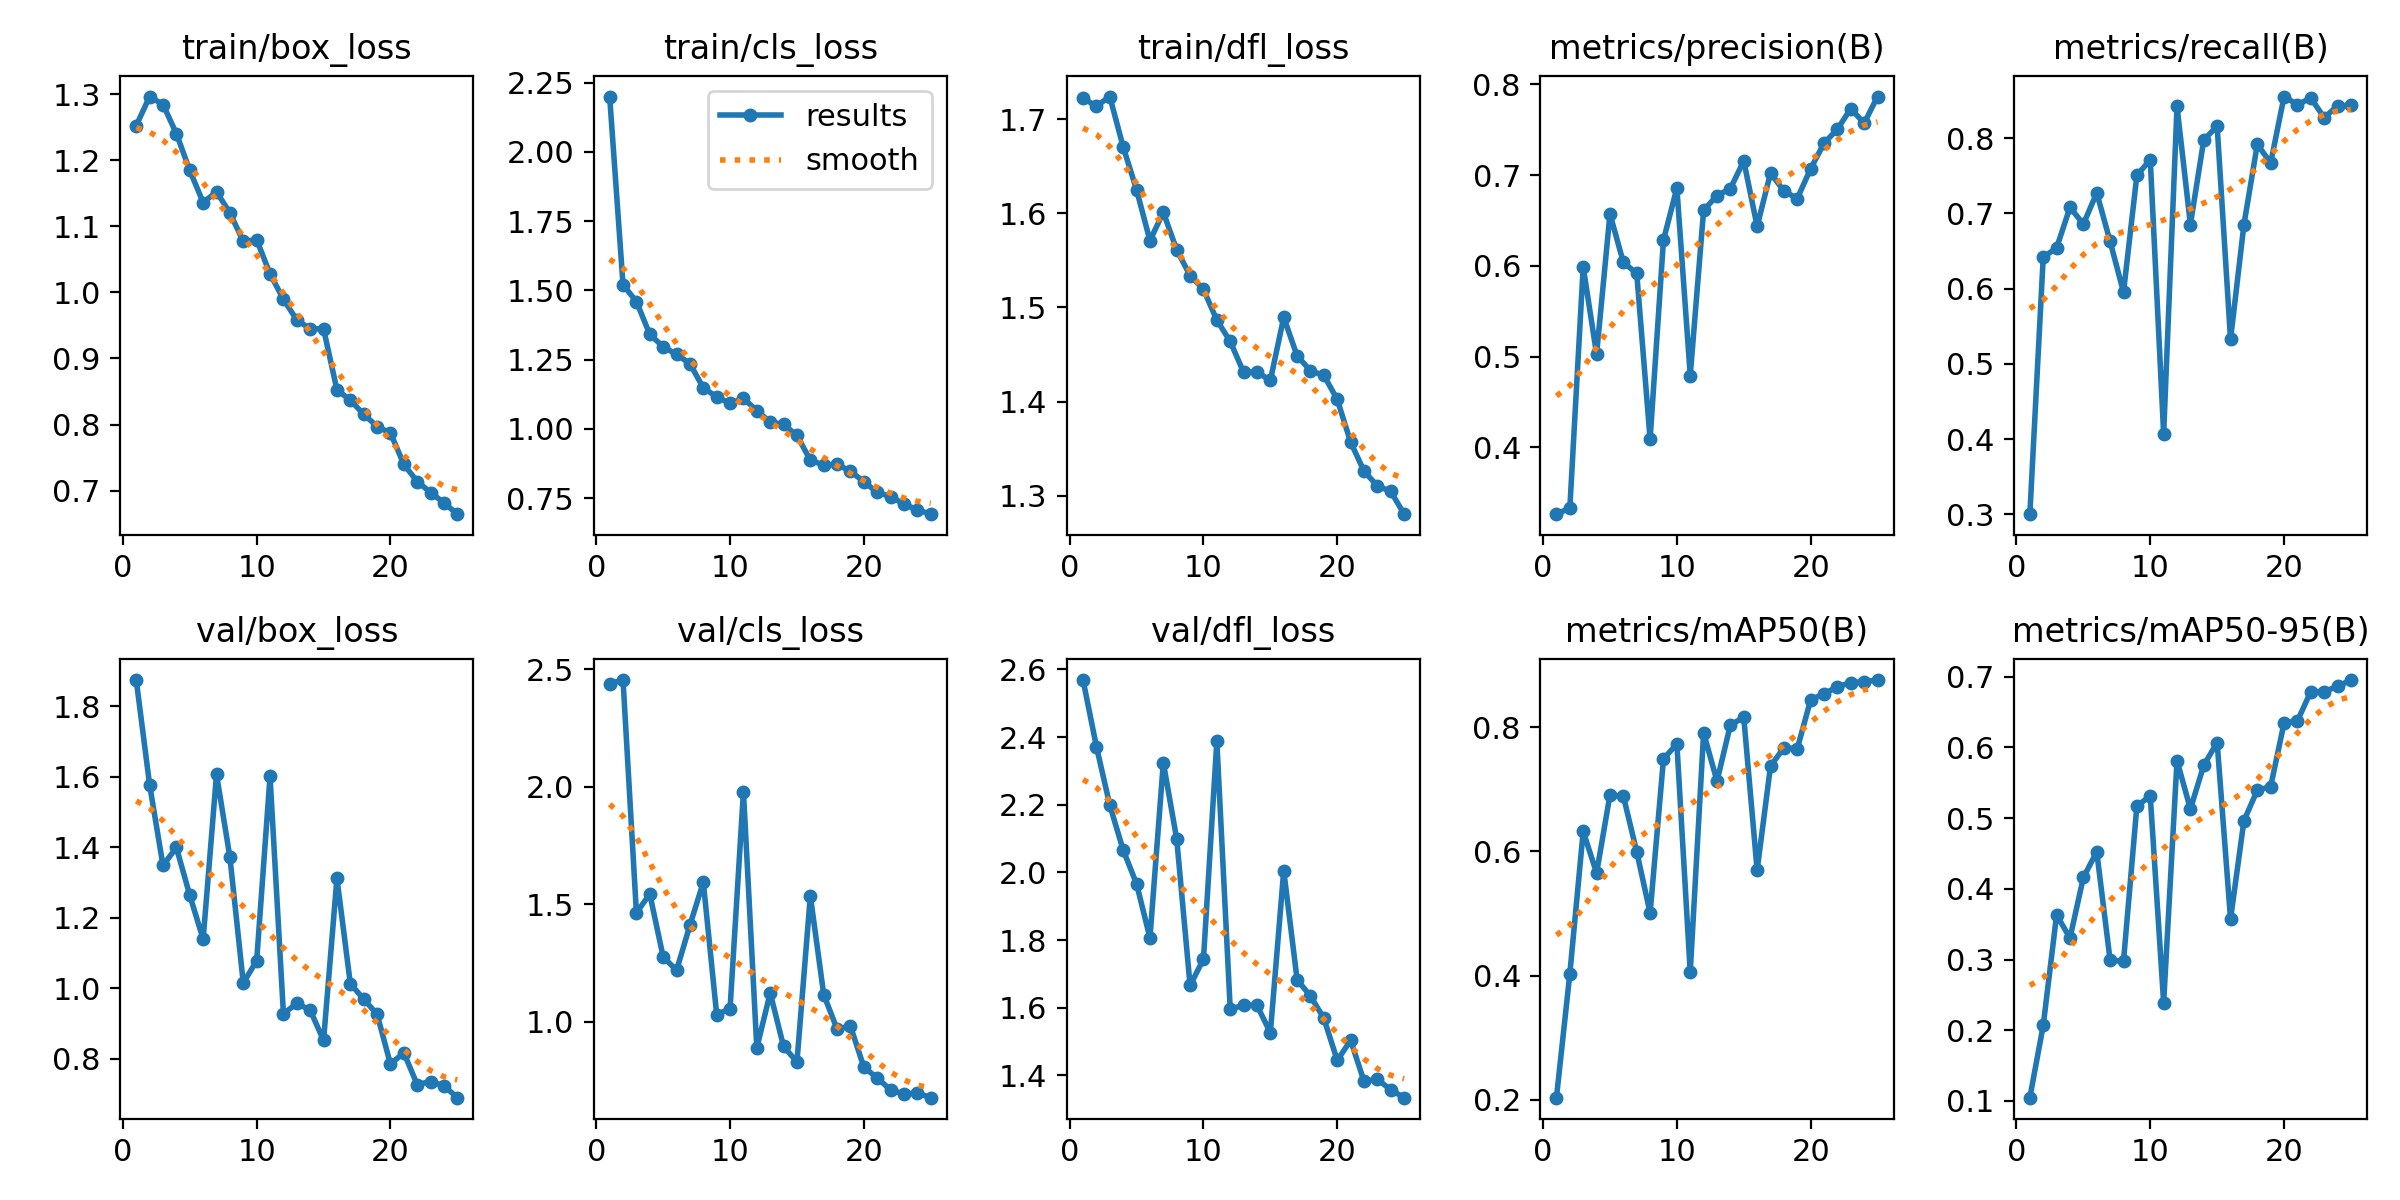

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/results.png', width=600)

/content


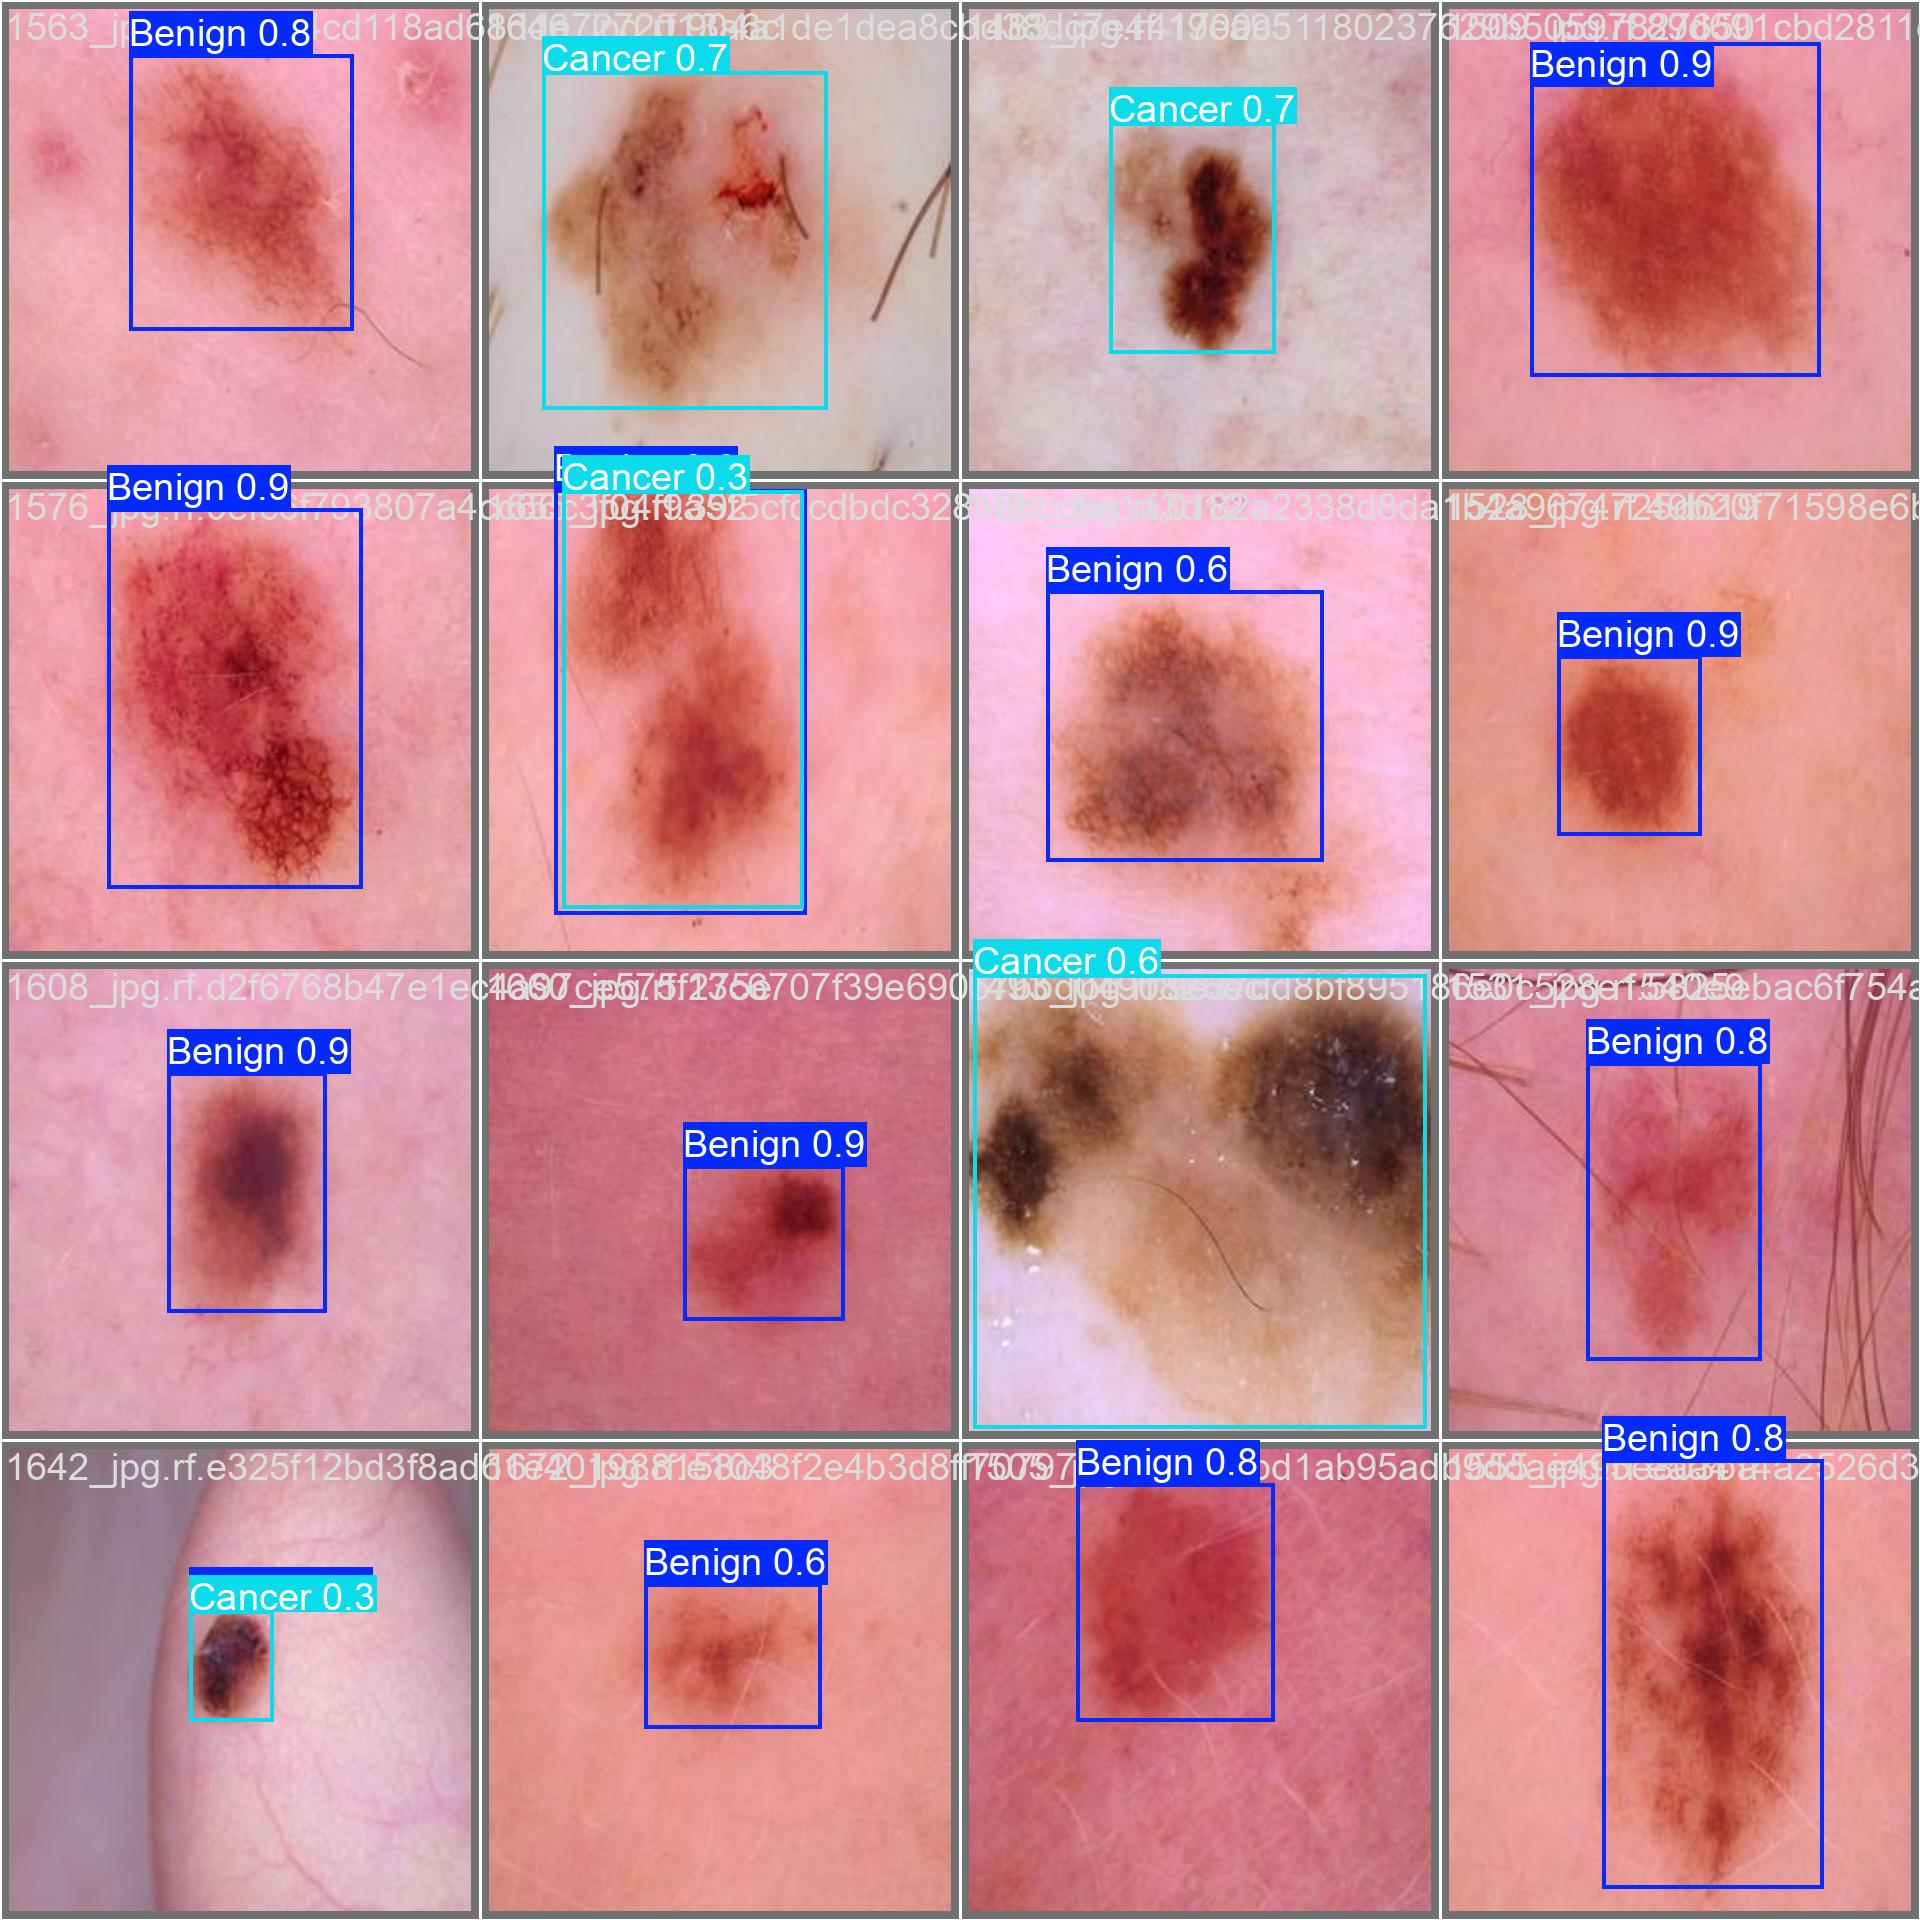

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/val_batch0_pred.jpg', width=600)

In [ ]:
%cd {HOME}

!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml

/content
Ultralytics YOLOv8.2.103 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 168 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Scanning /content/datasets/Skin-Cancer-1/valid/labels.cache... 400 images, 0 backgrounds, 0 corrupt: 100% 400/400 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 25/25 [00:03<00:00,  8.05it/s]
                   all        400        407      0.787      0.843      0.876      0.696
                Benign        200        206      0.823       0.82      0.909      0.744
                Cancer        200        201      0.751      0.866      0.843      0.647
Speed: 0.9ms preprocess, 2.0ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


In [ ]:
import pandas as pd
from ultralytics import YOLO

model = YOLO(f'{HOME}/runs/detect/train/weights/best.pt')

results = model.val(data=f'{dataset.location}/data.yaml')

names = list(results.names.values())

p_list = results.box.p.tolist()       # Precision listesi
r_list = results.box.r.tolist()       # Recall listesi
ap50_list = results.box.ap50.tolist() # mAP50 listesi
ap_list = results.box.ap.tolist()     # mAP50-95 listesi

metrics_data = []
for i, name in enumerate(names):
    metrics_data.append({
        "Class": name,
        "Precision": round(p_list[i], 3),
        "Recall": round(r_list[i], 3),
        "mAP@.5": round(ap50_list[i], 3),
        "mAP@.5:.95": round(ap_list[i], 3)
    })

all_stats = pd.DataFrame([{
    "Class": "all",
    "Precision": round(results.results_dict['metrics/precision(B)'], 3),
    "Recall": round(results.results_dict['metrics/recall(B)'], 3),
    "mAP@.5": round(results.results_dict['metrics/mAP50(B)'], 3),
    "mAP@.5:.95": round(results.results_dict['metrics/mAP50-95(B)'], 3)
}])

df_classes = pd.DataFrame(metrics_data)
final_table = pd.concat([all_stats, df_classes], ignore_index=True)

display(final_table)

Ultralytics YOLOv8.2.103 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 168 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs


val: Scanning /content/datasets/Skin-Cancer-1/valid/labels.cache... 400 images, 0 backgrounds, 0 corrupt: 100%|██████████| 400/400 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 25/25 [00:03<00:00,  8.16it/s]


                   all        400        407      0.787      0.843      0.876      0.696
                Benign        200        206      0.823       0.82      0.909      0.744
                Cancer        200        201      0.751      0.866      0.843      0.647
Speed: 0.9ms preprocess, 1.9ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to runs/detect/val2


,Class,Precision,Recall,mAP@.5,mAP@.5:.95
0,all,0.787,0.843,0.876,0.696
1,Benign,0.823,0.820,0.909,0.744
2,Cancer,0.751,0.866,0.843,0.647


In [ ]:
%cd {HOME}
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

/content
Ultralytics YOLOv8.2.103 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 168 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs

image 1/199 /content/datasets/Skin-Cancer-1/test/images/0013_jpg.rf.8a3791653d30332040cb5f9b7203f234.jpg: 800x800 1 Cancer, 6.4ms
image 2/199 /content/datasets/Skin-Cancer-1/test/images/0014_jpg.rf.9ddcdd6dd784f88b6fecdfe2b8275999.jpg: 800x800 1 Benign, 7.2ms
image 3/199 /content/datasets/Skin-Cancer-1/test/images/0022_jpg.rf.1fb84d65733e49c1699f6a2a01a96258.jpg: 800x800 1 Cancer, 6.3ms
image 4/199 /content/datasets/Skin-Cancer-1/test/images/0026_jpg.rf.25cf54aaf5e74585aa228063e043d2eb.jpg: 800x800 2 Cancers, 6.2ms
image 5/199 /content/datasets/Skin-Cancer-1/test/images/0027_jpg.rf.1a9aaed8ac34b1c4480e66bcd75d6f71.jpg: 800x800 1 Cancer, 6.3ms
image 6/199 /content/datasets/Skin-Cancer-1/test/images/0028_jpg.rf.182f1063c261a13363c4c0c46e8bcddd.jpg: 800x800 1 Benign, 1 Cancer, 6.4ms
image 7/199 /c

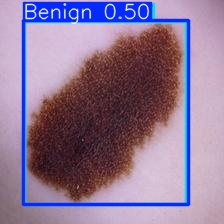

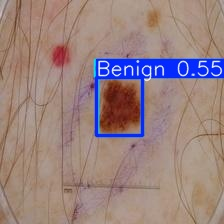

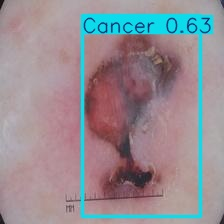

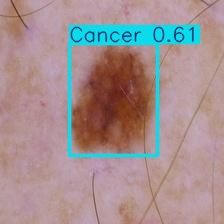

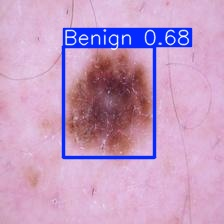

In [ ]:
import glob
from IPython.display import Image, display

base_path = '/content/runs/detect/'

subfolders = [os.path.join(base_path, d) for d in os.listdir(base_path)
              if os.path.isdir(os.path.join(base_path, d)) and d.startswith('predict')]

latest_folder = max(subfolders, key=os.path.getmtime)

image_paths = glob.glob(f'{latest_folder}/*.jpg')[:5]

for image_path in image_paths:
    display(Image(filename=image_path, width=600))
    print("\n")